<a href="https://colab.research.google.com/github/isaacrich080-ctrl/Project1/blob/main/Facial_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
! pip install tensorflow mtcnn scikit-learn tensorflow_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 34.9 MB/s eta 0:00:00


In [3]:
import os
import numpy as np
import tensorflow as tf
import tensorflow_hub as hub
from mtcnn import MTCNN
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import cv2
from tqdm.notebook import tqdm
import requests
import tarfile
import random
import pickle
from google.colab import drive

In [4]:
# 1
class FaceRecognitionSystem:
    def __init__(self):
        self.detector = MTCNN()
        # Load EfficientNet model directly using KerasLayer wrapper
        self.facenet_model_layer = hub.KerasLayer('https://tfhub.dev/tensorflow/efficientnet/lite0/feature-vector/2')
        self.required_size = (160, 160)
        self.embeddings = []
        self.labels = []
        self.le = LabelEncoder()
        self.classifier = SVC(kernel="linear", C=0.1, probability=True)

    def _extract_face(self, image):
        faces = self.detector.detect_faces(image)
        if not faces:
            return None

        x1, y1, width, height = faces[0]['box']
        x2, y2 = x1 + width, y1 + height

        face = image[y1:y2, x1:x2]
        face = cv2.resize(face, self.required_size)
        return face

    def _get_embedding(self, face):
        # Preprocess the face image
        face = face.astype('float32') / 255.0  # Normalize pixel values
        face = (face - 0.5) * 2.0  # Scale to [-1,1] if required

        # Add batch dimension and get embedding
        face_tensor = tf.convert_to_tensor([face])
        embedding = self.facenet_model_layer(face_tensor)
        return embedding.numpy()[0]

    def process_dataset(self, dataset_path, max_samples_per_person=20):
        person_samples = {}

        # First, find eligible people (those with enough samples)
        for person_name in os.listdir(dataset_path):
            person_dir = os.path.join(dataset_path, person_name)
            if os.path.isdir(person_dir):
                images = [f for f in os.listdir(person_dir)
                          if f.endswith(('.jpg', '.jpeg', '.png'))][:max_samples_per_person]
                if len(images) >= 20:  # changed from 35 so it matches max_samples_per_person=20
                    person_samples[person_name] = images

        print(f"Found {len(person_samples)} people with sufficient samples")

        # Process faces for each eligible person
        for person_name, images in tqdm(person_samples.items(), desc="Processing people"):
            successful_embeddings = 0
            for image_name in images:
                try:
                    image_path = os.path.join(dataset_path, person_name, image_name)
                    image = cv2.imread(image_path)
                    if image is None:
                        continue

                    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                    face = self._extract_face(image)

                    if face is not None:
                        embedding = self._get_embedding(face)
                        self.embeddings.append(embedding)
                        self.labels.append(person_name)
                        successful_embeddings += 1
                except Exception as e:
                    print(f"Error processing {image_path}: {str(e)}")

            if successful_embeddings > 0:
                print(f"Processed {successful_embeddings} images for {person_name}")

    def train_classifier(self):
        if len(self.embeddings) == 0:
            print("No embeddings to train on!")
            return None

        X = np.array(self.embeddings)
        encoded_labels = self.le.fit_transform(self.labels)

        X_train, X_test, y_train, y_test = train_test_split(
            X, encoded_labels, test_size=0.2, random_state=42
        )

        self.classifier.fit(X_train, y_train)

        y_pred = self.classifier.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)

        return {
            'accuracy': accuracy,
            'X_train': X_train,
            'X_test': X_test,
            'y_train': y_train,
            'y_test': y_test,
            'y_pred': y_pred
        }

In [9]:
#2 Download and extract LFW dataset
def download_and_extract_lfw():
    lfw_url = "http://vis-www.cs.umass.edu/lfw/lfw.tgz"
    local_filename = "lfw.tgz"

    if not os.path.exists('/content/lfw'):
        print("Downloading LFW dataset...")
        response = requests.get(lfw_url, stream=True)
        with open(local_filename, 'wb') as f:
            for chunk in response.iter_content(chunk_size=8192):
                f.write(chunk)

        print("Extracting dataset...")
        with tarfile.open(local_filename) as tar:
            tar.extractall('/content')

        os.remove(local_filename)
        print("Dataset ready!")
    else:
        print("LFW dataset already exists.")

    return '/content/lfw'

In [10]:
# 3 plot
def plot_results(results):
    if results is None:
        print("No results to plot!")
        return

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 2, 1)
    plt.title('Training Data Distribution')
    unique, counts = np.unique(results['y_train'], return_counts=True)
    plt.bar(unique[:10], counts[:10])  # Plot only first 10 classes for visibility
    plt.xlabel('Person ID (first 10)')
    plt.ylabel('Number of samples')

    plt.subplot(1, 2, 2)
    plt.title(f"Model Accuracy: {results['accuracy']:.2%}")
    cm = tf.math.confusion_matrix(results['y_test'], results['y_pred'])
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.colorbar()
    plt.xlabel('Predicted label')
    plt.ylabel('True label')

    plt.tight_layout()
    plt.show()

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Initializing Face Recognition System...


Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Processing dataset...
Found 62 people with sufficient samples


Processing people:   0%|          | 0/62 [00:00<?, ?it/s]

Processed 20 images for Winona_Ryder
Processed 20 images for Jennifer_Aniston
Processed 20 images for George_W_Bush
Processed 20 images for Juan_Carlos_Ferrero
Processed 20 images for Mahmoud_Abbas
Processed 20 images for Paul_Bremer
Processed 20 images for Donald_Rumsfeld
Processed 20 images for Jean_Chretien
Processed 20 images for Igor_Ivanov
Processed 20 images for Tiger_Woods
Processed 20 images for Kofi_Annan
Processed 20 images for Hans_Blix
Processed 20 images for Alvaro_Uribe
Processed 20 images for Alejandro_Toledo
Processed 20 images for Hamid_Karzai
Processed 20 images for Roh_Moo-hyun
Processed 20 images for Silvio_Berlusconi
Processed 20 images for Lindsay_Davenport
Processed 20 images for Guillermo_Coria
Processed 20 images for Pete_Sampras
Processed 20 images for Michael_Bloomberg
Processed 20 images for Junichiro_Koizumi
Processed 20 images for Serena_Williams
Processed 20 images for Luiz_Inacio_Lula_da_Silva
Processed 20 images for Saddam_Hussein
Processed 20 images f

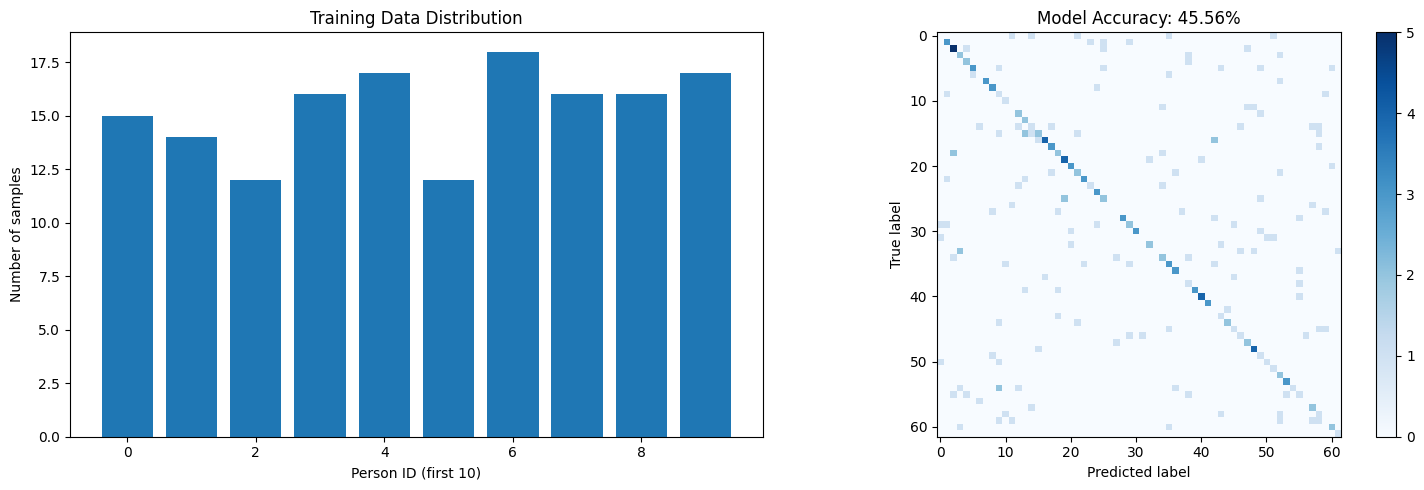


Classification Report:
                           precision    recall  f1-score   support

         Alejandro_Toledo       0.00      0.00      0.00         5
             Alvaro_Uribe       0.50      0.50      0.50         6
          Amelie_Mauresmo       0.56      0.62      0.59         8
             Andre_Agassi       0.33      0.50      0.40         4
           Angelina_Jolie       0.50      0.67      0.57         3
             Ariel_Sharon       0.75      0.38      0.50         8
    Arnold_Schwarzenegger       0.00      0.00      0.00         2
     Atal_Bihari_Vajpayee       1.00      0.75      0.86         4
             Bill_Clinton       0.60      0.75      0.67         4
             Carlos_Menem       0.12      0.33      0.18         3
             Colin_Powell       0.33      1.00      0.50         1
            David_Beckham       0.00      0.00      0.00         3
          Donald_Rumsfeld       0.40      0.67      0.50         3
         George_Robertson       0.33 

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
# 4
try:
    # Initialize system and process dataset
    print("Initializing Face Recognition System...")
    face_system = FaceRecognitionSystem()

    print("Processing dataset...")
    dataset_path = '/root/scikit_learn_data/lfw_home/lfw_funneled'

    face_system.process_dataset(
        dataset_path,
        max_samples_per_person=20
    )

    # Train classifier and get results
    print(f"Training classifier on {len(face_system.embeddings)} samples...")
    results = face_system.train_classifier()

    if results is not None:
        # Plot and display results
        plot_results(results)

        # Print classification report
        y_true = face_system.le.inverse_transform(results['y_test'])
        y_pred = face_system.le.inverse_transform(results['y_pred'])

        print("\nClassification Report:")
        print(classification_report(y_true, y_pred))

        # Save model
        save_path = '/content/drive/MyDrive/face_recognition_model.pkl'

        if os.path.exists('/content/drive'):
            import pickle

            model_data = {
                'classifier': face_system.classifier,
                'label_encoder': face_system.le
            }

            with open(save_path, 'wb') as f:
                pickle.dump(model_data, f)

            print(f"Model saved to Google Drive: {save_path}")

    else:
        print("Training failed due to lack of data")

except Exception as e:
    print(f"An error occurred: {str(e)}")
    raise

In [ ]:
import os
print("lfw folder exists:", os.path.exists('/content/lfw'))
print("files in /content:", os.listdir('/content'))


lfw folder exists: False
files in /content: ['.config', 'drive', 'sample_data']


In [7]:
from sklearn.datasets import fetch_lfw_people, get_data_home
import os

# Downloads and extracts LFW (the people with 20+ images get loaded, which is all we need)
fetch_lfw_people(min_faces_per_person=20, download_if_missing=True)

src = os.path.join(get_data_home(), 'lfw_home', 'lfw_funneled')
print("Dataset folder:", src)
print("People folders:", len(os.listdir(src)))

# Make it available at /content/lfw so Cell 5 works unchanged
if not os.path.exists('/content/lfw'):
    os.symlink(src, '/content/lfw')
print("lfw ready:", os.path.exists('/content/lfw'))

Dataset folder: /root/scikit_learn_data/lfw_home/lfw_funneled
People folders: 5760
lfw ready: True


# **Facial Recognition Part2 BY faces**

In [11]:
class FaceRecognitionDemo:
    def __init__(self, model_path):
        # Load the saved model and components
        with open(model_path, 'rb') as f:
            model_data = pickle.load(f)

        self.classifier = model_data['classifier']
        self.le = model_data['label_encoder']
        self.detector = MTCNN()

        # Load EfficientNet model using KerasLayer
        self.facenet_model_layer = hub.KerasLayer('https://tfhub.dev/tensorflow/efficientnet/lite0/feature-vector/2')
        self.required_size = (160, 160)

    def process_image(self, image):
        rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        faces = self.detector.detect_faces(rgb_image)

        if not faces:
            return None, None

        x1, y1, width, height = faces[0]['box']
        x2, y2 = x1 + width, y1 + height

        face = rgb_image[y1:y2, x1:x2]
        face_resized = cv2.resize(face, self.required_size)

        # Normalize and scale image to [-1, 1]
        face_array = face_resized.astype('float32') / 255.0
        face_normalized = (face_array - 0.5) * 2.0

        # Prepare input for EfficientNet
        face_tensor = tf.convert_to_tensor([face_normalized])
        embedding = self.facenet_model_layer(face_tensor).numpy()[0]

        return embedding, (x1, y1, x2, y2)

    def predict(self, image):
        embedding, face_box = self.process_image(image)
        if embedding is None:
            return None, None, None

        # Predict
        pred_proba = self.classifier.predict_proba([embedding])[0]
        pred_class = np.argmax(pred_proba)
        confidence = pred_proba[pred_class]
        predicted_name = self.le.inverse_transform([pred_class])[0]

        return predicted_name, confidence, face_box


In [12]:
def get_random_test_images(lfw_path, num_images=5):
    all_people = [d for d in os.listdir(lfw_path) if os.path.isdir(os.path.join(lfw_path, d))]
    selected_people = random.sample(all_people, num_images)

    test_images = []
    for person in selected_people:
        person_dir = os.path.join(lfw_path, person)
        images = os.listdir(person_dir)
        selected_image = random.choice(images)
        image_path = os.path.join(person_dir, selected_image)
        image = cv2.imread(image_path)
        test_images.append((person, image))

    return test_images


In [13]:

def display_results(test_images, predictions):
    plt.figure(figsize=(20, 4))
    for i, ((true_name, image), (pred_name, confidence, face_box)) in enumerate(zip(test_images, predictions)):
        plt.subplot(1, len(test_images), i+1)

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        if face_box:
            x1, y1, x2, y2 = face_box
            cv2.rectangle(image_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)

        plt.imshow(image_rgb)
        if pred_name is None:
            result_text = f"True: {true_name}\nNo face detected"

In [15]:
def display_results(test_images, predictions):
    plt.figure(figsize=(20, 4))
    for i, ((true_name, image), (pred_name, confidence, face_box)) in enumerate(zip(test_images, predictions)):
        plt.subplot(1, len(test_images), i+1)

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        if face_box:
            x1, y1, x2, y2 = face_box
            cv2.rectangle(image_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)

        plt.imshow(image_rgb)
        if pred_name is None:
            result_text = f"True: {true_name}\nNo face detected"
        else:
            result_text = f"True: {true_name}\nPredicted: {pred_name}\nConfidence: {confidence:.2%}"

        plt.title(result_text)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

Mounted at /content/drive
Initializing demo system...


Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Getting test images...
Making predictions...
Displaying results...


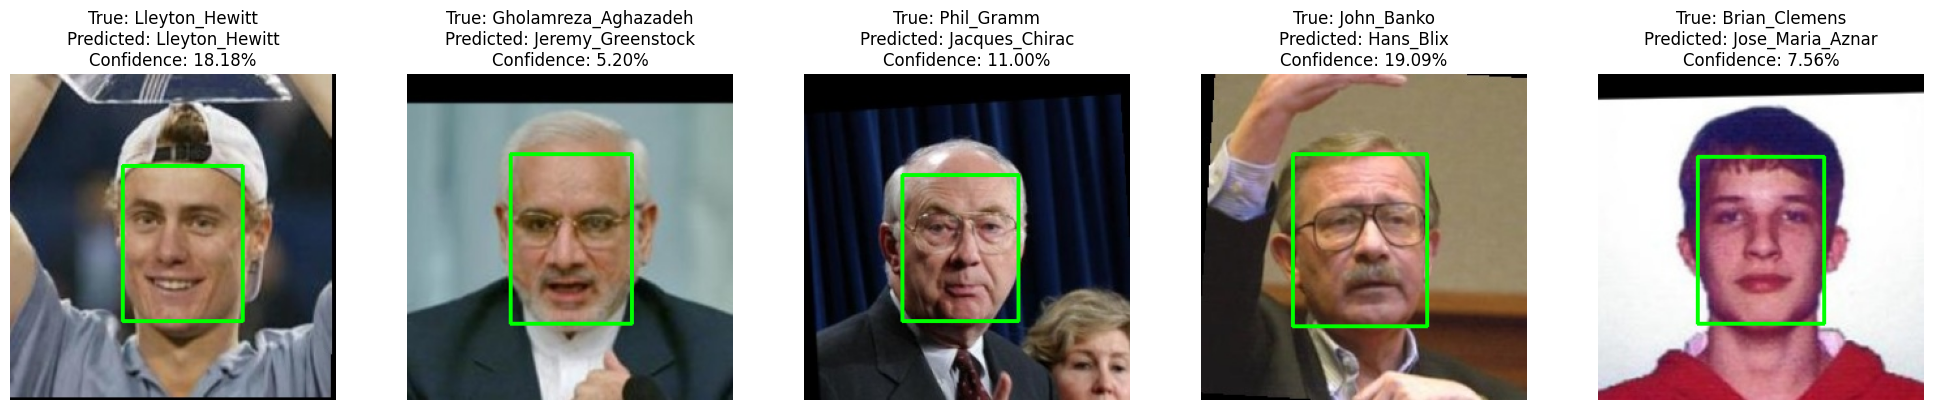

✓ True: Lleyton_Hewitt       Predicted: Lleyton_Hewitt       Confidence: 18.18%
✗ True: Gholamreza_Aghazadeh Predicted: Jeremy_Greenstock    Confidence: 5.20%
✗ True: Phil_Gramm           Predicted: Jacques_Chirac       Confidence: 11.00%
✗ True: John_Banko           Predicted: Hans_Blix            Confidence: 19.09%
✗ True: Brian_Clemens        Predicted: Jose_Maria_Aznar     Confidence: 7.56%


In [16]:
try:
    # Mount Google Drive to access the saved model
    drive.mount('/content/drive')
    model_path = '/content/drive/MyDrive/face_recognition_model.pkl'

    # Initialize the demo system
    print("Initializing demo system...")
    demo_system = FaceRecognitionDemo(model_path)

    # Get random test images
    print("Getting test images...")
    lfw_path = '/content/lfw'
    test_images = get_random_test_images(lfw_path, num_images=5)

    # Make predictions
    print("Making predictions...")
    predictions = []
    for _, image in test_images:
        pred_name, confidence, face_box = demo_system.predict(image)
        predictions.append((pred_name, confidence, face_box))

    # Display results
    print("Displaying results...")
    display_results(test_images, predictions)

    # Calculate and display metrics
    correct_predictions = sum(1 for (true_name, _), (pred_name, _, _)
                              in zip(test_images, predictions)
                              if pred_name is not None and true_name == pred_name)
    for (true_name, _), (pred_name, confidence, _) in zip(test_images, predictions):
        if pred_name is None:
            print(f"✗ True: {true_name:<20} No face detected")
        else:
            status = "✓" if true_name == pred_name else "✗"
            print(f"{status} True: {true_name:<20} Predicted: {pred_name:<20} Confidence: {confidence:.2%}")

except Exception as e:
    print(f"An error occurred: {str(e)}")
    raise
